**PART 1: Dataset Collection, Preprocessing and Exploratory Analysis**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
print("--- First 5 Rows of Dataset ---")

df = pd.read_csv('dataset.csv')
display(df.head())

--- First 5 Rows of Dataset ---


,network_asn_type,ip_subnet_velocity_1h,dns_ip_mismatch,ip_to_claimed_address_distance_km,vpn_datacenter_port_open,device_canvas_webgl_hash,device_hash_velocity_24h,browser_timezone_mismatch,headless_browser_flag,battery_status_anomalies,time_to_completion_ms,form_paste_count,keystroke_flight_time_std_dev,cursor_trajectory_entropy,backspace_correction_rate,email_domain_risk_tier,email_levenshtein_proximity,phone_carrier_type,identity_attribute_age_days,target_is_fraud_ring
0,Residential_ISP,3,False,5.91,False,webgl_003dcf4558ee,1,False,False,False,29808,0,62.49,3.853,0.0129,Tier 2,11,Mobile,257.0,0
1,Residential_ISP,2,True,1274.04,False,webgl_emufarm00007,29,True,True,True,7507,4,5.76,0.431,0.0004,Tier 4,3,Mobile,1.3,1
2,Residential_ISP,2,False,3.66,False,webgl_0018520a1180,1,False,False,False,63893,0,41.26,3.911,0.1673,Tier 1,12,Mobile,320.4,0
3,Residential_ISP,2,True,10.20,False,webgl_00863f491bb5,1,False,False,False,41367,0,54.06,4.330,0.1963,Tier 1,19,Mobile,430.9,0
4,Proxy_Network,9,False,257.86,True,webgl_synring00002,17,True,False,False,49170,8,18.31,2.316,0.0194,Tier 1,4,VoIP,1.3,1


In [ ]:
np.random.seed(123)
noise_indices = np.random.choice(df.index, size=int(len(df) * 0.015), replace=False)
df.loc[noise_indices, 'target_is_fraud_ring'] = 1 - df.loc[noise_indices, 'target_is_fraud_ring']

In [ ]:
print("\n--- Statistical Summary ---")
display(df.describe())


--- Statistical Summary ---


,ip_subnet_velocity_1h,ip_to_claimed_address_distance_km,device_hash_velocity_24h,time_to_completion_ms,form_paste_count,keystroke_flight_time_std_dev,cursor_trajectory_entropy,backspace_correction_rate,email_levenshtein_proximity,identity_attribute_age_days,target_is_fraud_ring
count,2500.000000,2440.000000,2500.000000,2500.000000,2500.000000,2434.000000,2500.000000,2500.000000,2500.000000,2453.000000,2500.000000
mean,5.536400,493.905516,5.790000,39941.073600,1.096000,46.836680,3.584967,0.077563,11.259200,601.575214,0.187600
std,11.270186,1202.962265,11.226233,23686.121621,1.923815,22.475201,1.438319,0.060339,5.229432,522.197866,0.390471
min,1.000000,0.400000,1.000000,387.000000,0.000000,0.010000,0.010000,0.000000,1.000000,0.000000,0.000000
25%,2.000000,6.415000,1.000000,26506.500000,0.000000,35.742500,3.161750,0.030100,9.000000,207.700000,0.000000
50%,2.000000,14.120000,1.000000,37781.500000,0.000000,50.890000,3.951000,0.070200,12.000000,504.400000,0.000000
75%,3.000000,58.975000,1.000000,51879.750000,1.000000,62.267500,4.522000,0.113625,15.000000,874.300000,0.000000
max,83.000000,9422.160000,60.000000,165000.000000,8.000000,103.460000,6.200000,0.320000,25.000000,3650.000000,1.000000


In [ ]:
print("\n--- Mean, Median, Mode, Variance, and Std Deviation ---")
numeric_cols = ['ip_subnet_velocity_1h', 'time_to_completion_ms', 'keystroke_flight_time_std_dev']
for col in numeric_cols:
    print(f"Column: {col}")
    print(f" Mean: {df[col].mean():.2f}")
    print(f" Median: {df[col].median():.2f}")
    print(f" Mode: {df[col].mode()[0]}")
    print(f" Variance: {df[col].var():.2f}")
    print(f" Std Dev: {df[col].std():.2f}\n")


--- Mean, Median, Mode, Variance, and Std Deviation ---
Column: ip_subnet_velocity_1h
 Mean: 5.54
 Median: 2.00
 Mode: 2
 Variance: 127.02
 Std Dev: 11.27

Column: time_to_completion_ms
 Mean: 39941.07
 Median: 37781.50
 Mode: 11500
 Variance: 561032357.47
 Std Dev: 23686.12

Column: keystroke_flight_time_std_dev
 Mean: 46.84
 Median: 50.89
 Mode: 16.5
 Variance: 505.13
 Std Dev: 22.48



In [ ]:
print("--- Missing Values Before Preprocessing ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- Missing Values Before Preprocessing ---
ip_to_claimed_address_distance_km    60
keystroke_flight_time_std_dev        66
identity_attribute_age_days          47
dtype: int64


In [ ]:
# Replacing missing values with Median
df['keystroke_flight_time_std_dev'].fillna(df['keystroke_flight_time_std_dev'].median(), inplace=True)
df['ip_to_claimed_address_distance_km'].fillna(df['ip_to_claimed_address_distance_km'].median(), inplace=True)
df['identity_attribute_age_days'].fillna(df['identity_attribute_age_days'].median(), inplace=True)

/tmp/ipykernel_8426/2750352775.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['keystroke_flight_time_std_dev'].fillna(df['keystroke_flight_time_std_dev'].median(), inplace=True)
/tmp/ipykernel_8426/2750352775.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, 

In [ ]:
categorical_columns = df.select_dtypes(include=["object","string"]).columns
print(categorical_columns)

Index(['network_asn_type', 'device_canvas_webgl_hash',
       'email_domain_risk_tier', 'phone_carrier_type'],
      dtype='object')


In [ ]:
#Handle the high-cardinality device hash string by converting it to a frequency count
hash_counts = df['device_canvas_webgl_hash'].value_counts()
df['webgl_hash_frequency'] = df['device_canvas_webgl_hash'].map(hash_counts)
df = df.drop('device_canvas_webgl_hash', axis=1)


#Convert boolean (True/False) columns to 1/0 integers
bool_columns = df.select_dtypes(include=['bool']).columns
df[bool_columns] = df[bool_columns].astype(int)

#One-Hot Encoding for categorical strings using drop_first to avoid Dummy Variable Trap
categorical_columns = ['network_asn_type', 'email_domain_risk_tier', 'phone_carrier_type']
df = pd.get_dummies(df, columns=categorical_columns, drop_first=True, dtype=int)

/tmp/ipykernel_8426/2570472759.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['target_is_fraud_ring'], y=df['time_to_completion_ms'], palette='Set2')


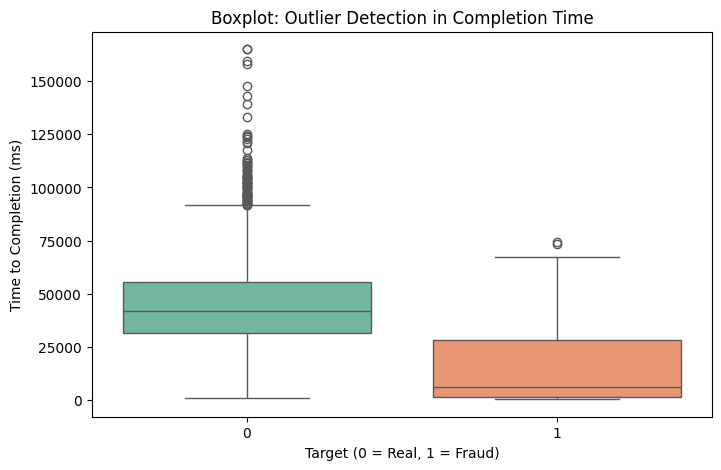

In [ ]:
# Outlier Detection using Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['target_is_fraud_ring'], y=df['time_to_completion_ms'], palette='Set2')
plt.title("Boxplot: Outlier Detection in Completion Time")
plt.xlabel("Target (0 = Real, 1 = Fraud)")
plt.ylabel("Time to Completion (ms)")
plt.show()

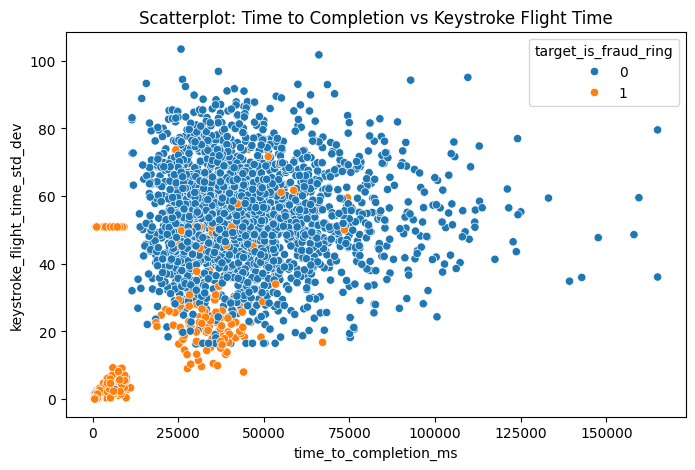

In [ ]:
# Scatterplot showing relationship
plt.figure(figsize=(8, 5))
sns.scatterplot(x='time_to_completion_ms', y='keystroke_flight_time_std_dev', hue='target_is_fraud_ring', data=df)
plt.title("Scatterplot: Time to Completion vs Keystroke Flight Time")
plt.show()

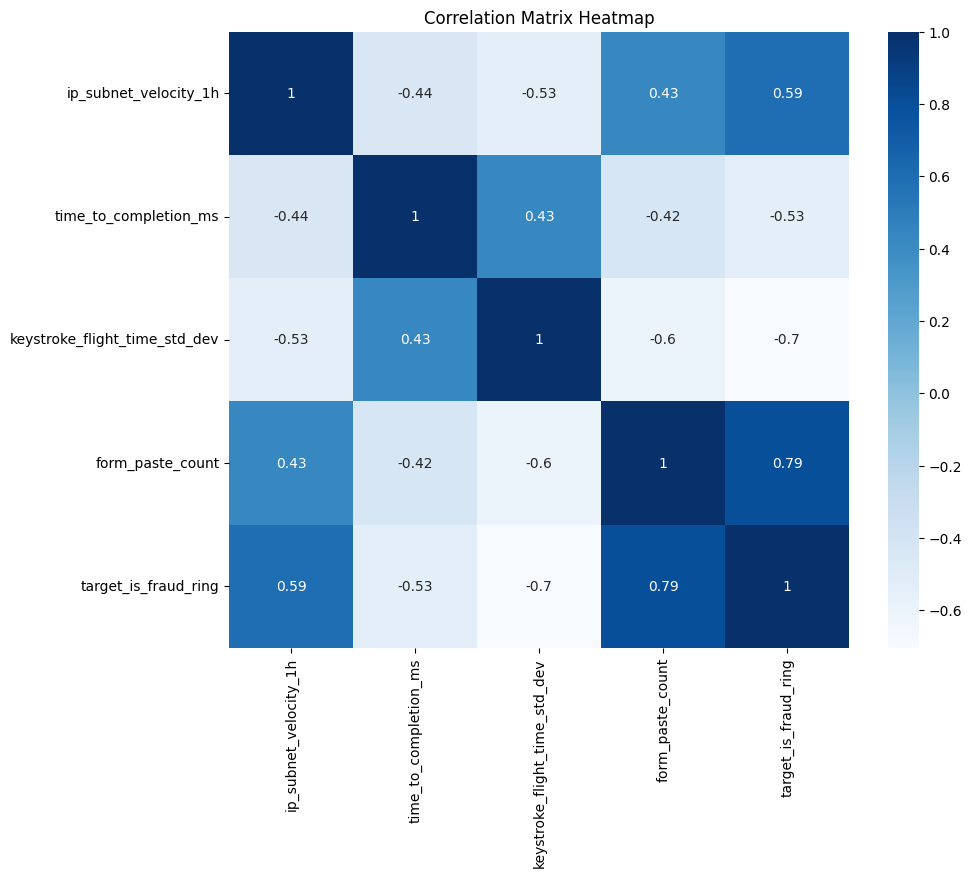

In [ ]:
# Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df[['ip_subnet_velocity_1h', 'time_to_completion_ms', 'keystroke_flight_time_std_dev',
                  'form_paste_count', 'target_is_fraud_ring']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Blues')
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
# 8. Splitting the Dataset, 80-20 Train-Test Split and Feature Scaling
from sklearn.model_selection import train_test_split
X = df.drop('target_is_fraud_ring', axis=1)
y = df['target_is_fraud_ring']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**PART 2: Implementation and Technical Progress**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report


========== 1. LOGISTIC REGRESSION ==========
Accuracy: 0.996
Classification Report:
               precision    recall  f1-score   support

        Real       0.99      1.00      1.00       394
       Fraud       1.00      0.98      0.99       106

    accuracy                           1.00       500
   macro avg       1.00      0.99      0.99       500
weighted avg       1.00      1.00      1.00       500



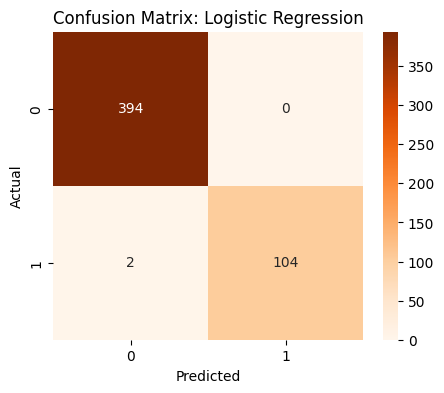

In [ ]:
print("\n========== 1. LOGISTIC REGRESSION ==========")
log_model = LogisticRegression(random_state=42, max_iter=1000)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Classification Report:\n", classification_report(y_test, y_pred_log, target_names=['Real', 'Fraud']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt='d', cmap='Oranges')
plt.title('Confusion Matrix: Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
print("\n========== 2. K-NEAREST NEIGHBORS (KNN) ==========")
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Classification Report:\n", classification_report(y_test, y_pred_knn, target_names=['Real', 'Fraud']))


========== 2. K-NEAREST NEIGHBORS (KNN) ==========
Accuracy: 0.996
Classification Report:
               precision    recall  f1-score   support

        Real       0.99      1.00      1.00       394
       Fraud       1.00      0.98      0.99       106

    accuracy                           1.00       500
   macro avg       1.00      0.99      0.99       500
weighted avg       1.00      1.00      1.00       500



In [ ]:
print("\n========== 3. NAIVE BAYES ==========")
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Classification Report:\n", classification_report(y_test, y_pred_nb, target_names=['Real', 'Fraud']))


========== 3. NAIVE BAYES ==========
Accuracy: 0.986
Classification Report:
               precision    recall  f1-score   support

        Real       0.99      0.99      0.99       394
       Fraud       0.95      0.98      0.97       106

    accuracy                           0.99       500
   macro avg       0.97      0.98      0.98       500
weighted avg       0.99      0.99      0.99       500



**PART 3: Final Project Analysis & Conclusion Graphs**

In [ ]:
metrics_data = {
    'Model': ['Logistic Regression', 'KNN (K=7)', 'Naive Bayes'],

    'Accuracy': [accuracy_score(y_test, y_pred_log),
                 accuracy_score(y_test, y_pred_knn),
                 accuracy_score(y_test, y_pred_nb)],

    'Precision': [precision_score(y_test, y_pred_log),
                  precision_score(y_test, y_pred_knn),
                  precision_score(y_test, y_pred_nb)],

    'Recall': [recall_score(y_test, y_pred_log),
               recall_score(y_test, y_pred_knn),
               recall_score(y_test, y_pred_nb)],

    'F1-Score': [f1_score(y_test, y_pred_log),
                 f1_score(y_test, y_pred_knn),
                 f1_score(y_test, y_pred_nb)]
}

results_df = pd.DataFrame(metrics_data)
results_df.set_index('Model', inplace=True)

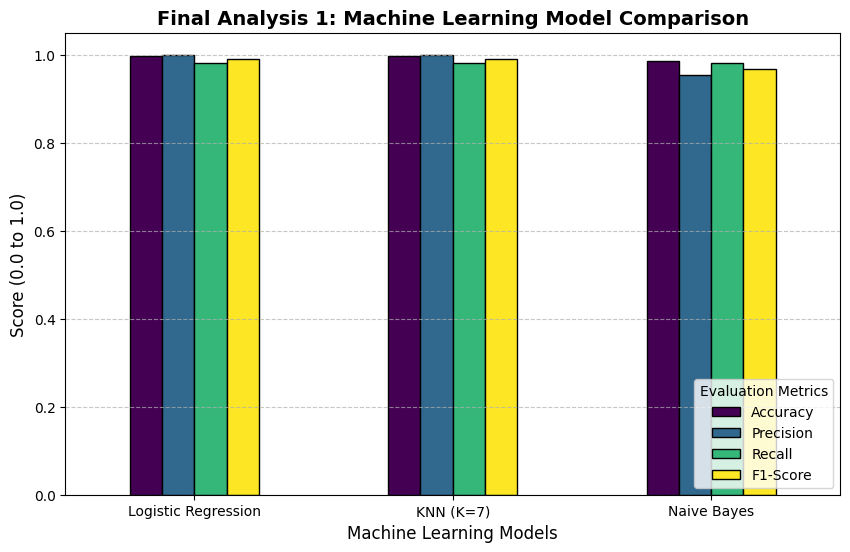

In [ ]:
# GRAPH 1: Model Performance Comparison (Grouped Bar Chart)

ax = results_df.plot(kind='bar', figsize=(10, 6), colormap='viridis', edgecolor='black')

plt.title('Final Analysis 1: Machine Learning Model Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Machine Learning Models', fontsize=12)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.xticks(rotation=0) # Keeps the model names horizontal and readable
plt.legend(loc='lower right', title="Evaluation Metrics")
plt.grid(axis='y', linestyle='--', alpha=0.7) # Adds faint background lines for readability
plt.show()

/tmp/ipykernel_8426/4166831645.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='coolwarm')


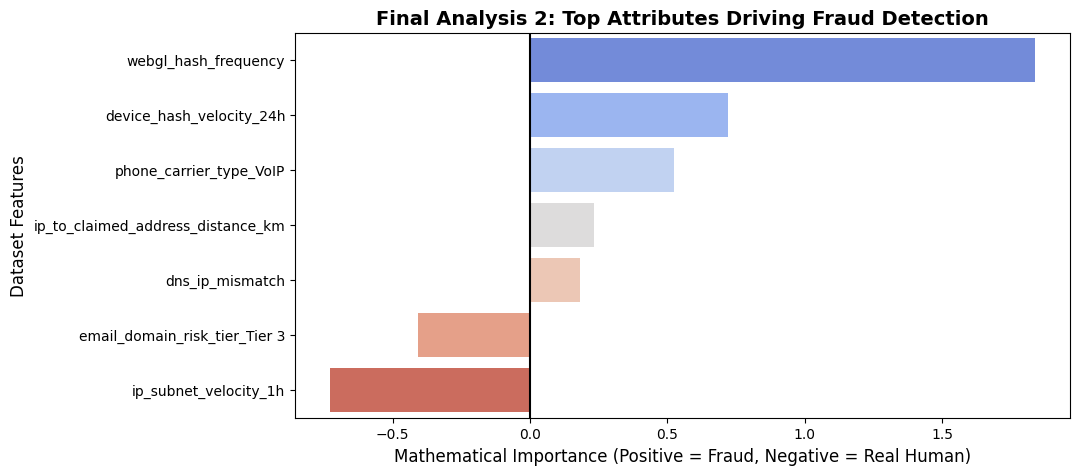

In [ ]:
# GRAPH 2: Feature Importance (How the AI caught the Fraudsters)

coefficients = log_model.coef_[0]

feature_importance = pd.Series(coefficients, index=X.columns).sort_values(ascending=False)

top_features = pd.concat([feature_importance.head(5), feature_importance.tail(2)])

plt.figure(figsize=(10, 5))

sns.barplot(x=top_features.values, y=top_features.index, palette='coolwarm')

plt.title('Final Analysis 2: Top Attributes Driving Fraud Detection', fontsize=14, fontweight='bold')
plt.xlabel('Mathematical Importance (Positive = Fraud, Negative = Real Human)', fontsize=12)
plt.ylabel('Dataset Features', fontsize=12)
plt.axvline(x=0, color='black', linewidth=1.5)
plt.show()